# HW3 · Notebook 2b: XLM-R на 80k текстів (1 епоха)

Експеримент: більше даних замість другої епохи (у Notebook 2 друга епоха не дала приросту). Val той самий, 8000 текстів; train = 32k з фіксованої вибірки + 48k інших текстів з train.csv.

- Той самий фіксований спліт, що в Notebook 1 (той самий seed і код), тож порівняння з TF-IDF чесне.
- Тренуємо `xlm-roberta-base` на **head+tail** обрізанні (перші 128 + останні 382 токени).
- Потім тією самою моделлю передбачаємо трьома способами: **head-only**, **head+tail**, **chunks** (усереднення по шматках по 510 токенів).
  Це перший експеримент з обробки довгих текстів.
- Зберігаємо ймовірності на val і test для ансамблю та підбору порогів у Notebook 3.

**Запуск:** Accelerator = GPU T4, Internet = On. Спочатку `DEBUG = True` у draft-сесії (2–3 хв, перевірка, що нічого не падає),
потім `DEBUG = False` і **Save Version → Save & Run All**, щоб рахувалося у фоні.

In [1]:
DEBUG = False          # True: швидка перевірка на маленькій підвибірці

import os, glob, time, random, copy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

SEED = 42
MODEL_NAME = 'xlm-roberta-base'
MAX_LEN = 512                 # з [CLS] і [SEP]
BODY = MAX_LEN - 2            # токени тексту
HEAD = 128                    # head+tail: 128 з початку, 382 з кінця
MAX_CHUNKS = 8                # для chunk-інференсу (8 × 510 токенів покриває майже всі тексти)
EPOCHS, BS, LR, WARMUP = 1, 16, 2e-5, 0.06
EXTRA_TRAIN = 48_000                # скільки додаткових текстів train узяти поза фіксованою вибіркою 40k
LABELS = ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

train_path = glob.glob('/kaggle/input/**/train.csv', recursive=True) or ['data/train.csv']
DATA_DIR = os.path.dirname(train_path[0])
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else 'out'
os.makedirs(OUT_DIR, exist_ok=True)
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
sample_sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')

cuda Tesla T4


## 1. Той самий фіксований спліт

In [2]:
# той самий код і seed, що в Notebook 1, тому вибірка ідентична
strat = train['label'] + '_' + train['lang']
sample, _ = train_test_split(train, train_size=40_000, stratify=strat, random_state=SEED)
tr, val = train_test_split(sample, test_size=0.2, stratify=sample['label'] + '_' + sample['lang'],
                           random_state=SEED)

# якщо split.csv з Notebook 1 підключений як input, перевіряємо, що спліт справді той самий
saved = glob.glob('/kaggle/input/**/split.csv', recursive=True)
if saved:
    s = pd.read_csv(saved[0])
    assert set(s.loc[s.split == 'val', 'id']) == set(val['id']), 'Спліт не збігається з Notebook 1!'
    print('Спліт збігається з Notebook 1')

if EXTRA_TRAIN:
    # val не змінюється; додаємо в train тексти, яких немає ні у фіксованій вибірці, ні у val
    rest = train[~train['id'].isin(sample['id'])]
    extra, _ = train_test_split(rest, train_size=EXTRA_TRAIN, stratify=rest['label'] + '_' + rest['lang'],
                                random_state=SEED)
    tr = pd.concat([tr, extra])

if DEBUG:
    tr, val, test = tr.sample(400, random_state=SEED), val.sample(200, random_state=SEED), test.head(300)
print('train:', len(tr), '| val:', len(val), '| test:', len(test))

Спліт збігається з Notebook 1
train: 80000 | val: 8000 | test: 25000


## 2. Токенізація і три способи обрізання

Токенізуємо повний текст один раз, а далі з тих самих токенів будуємо три варіанти входу.
- *head-only*: втрачає кінець тексту;
- *head+tail*: початок дає тему і "шапку" (часто людську навіть у fusion), кінець — висновки, де LLM пише найшаблонніше;
- *chunks*: модель бачить увесь текст шматками. Для fusion це важливо: переписана LLM частина може бути будь-де.

In [3]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.model_max_length = 10**7   # токенізуємо повний текст без попередження, обрізаємо самі

def encode(texts):
    return tok(list(texts), add_special_tokens=False, truncation=False)['input_ids']

t0 = time.time()
ids_tr, ids_val, ids_test = encode(tr['text']), encode(val['text']), encode(test['text'])
lens = np.array([len(x) for x in ids_val])
print(f'токенізація {time.time() - t0:.0f}s | val: медіана {np.median(lens):.0f} токенів, '
      f'> {BODY}: {(lens > BODY).mean():.1%}')

def head_only(ids):  return ids[:BODY]
def head_tail(ids):  return ids if len(ids) <= BODY else ids[:HEAD] + ids[-(BODY - HEAD):]
def to_chunks(ids):  return [ids[i:i + BODY] for i in range(0, max(len(ids), 1), BODY)][:MAX_CHUNKS]

y_tr = np.array([L2I[l] for l in tr['label']])
y_val = np.array([L2I[l] for l in val['label']])

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

токенізація 122s | val: медіана 670 токенів, > 510: 64.6%


In [4]:
def collate(batch):
    seqs, labels = zip(*batch)
    seqs = [[tok.cls_token_id] + s + [tok.sep_token_id] for s in seqs]
    width = max(len(s) for s in seqs)
    input_ids = torch.full((len(seqs), width), tok.pad_token_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), width), dtype=torch.long)
    for i, s in enumerate(seqs):
        input_ids[i, :len(s)] = torch.tensor(s); mask[i, :len(s)] = 1
    return input_ids, mask, torch.tensor(labels)

@torch.no_grad()
def predict_seqs(model, seqs, bs=64):
    # сортуємо за довжиною, щоб менше паддінгу -> швидше; потім повертаємо порядок
    order = np.argsort([len(s) for s in seqs])
    loader = DataLoader([(seqs[i], 0) for i in order], batch_size=bs, collate_fn=collate)
    model.eval(); out = []
    for input_ids, mask, _ in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=device == 'cuda'):
            logits = model(input_ids=input_ids.to(device), attention_mask=mask.to(device)).logits
        out.append(torch.softmax(logits.float(), -1).cpu().numpy())
    probs = np.empty((len(seqs), len(LABELS)), dtype=np.float32)
    probs[order] = np.concatenate(out)
    return probs

def predict(model, all_ids, mode):
    if mode == 'head':     return predict_seqs(model, [head_only(x) for x in all_ids])
    if mode == 'headtail': return predict_seqs(model, [head_tail(x) for x in all_ids])
    # chunks: передбачаємо кожен шматок, потім середнє і максимум по шматках кожного тексту
    owner, seqs = [], []
    for i, x in enumerate(all_ids):
        for c in to_chunks(x):
            owner.append(i); seqs.append(c)
    p = pd.DataFrame(predict_seqs(model, seqs)).assign(owner=owner).groupby('owner')
    return p.mean().values.astype(np.float32), p.max().values.astype(np.float32)

macro_f1 = lambda y, p: f1_score(y, p.argmax(1), average='macro')

## 3. Fine-tuning (head+tail)

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I).to(device)

train_seqs = [head_tail(x) for x in ids_tr]
loader = DataLoader(list(zip(train_seqs, y_tr)), batch_size=BS, shuffle=True, collate_fn=collate,
                    generator=torch.Generator().manual_seed(SEED))
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP * total_steps), total_steps)
scaler = torch.amp.GradScaler(enabled=device == 'cuda')

best_f1, best_state, history = -1, None, []
for epoch in range(EPOCHS):
    model.train(); t0 = time.time(); running = 0
    for step, (input_ids, mask, labels) in enumerate(loader, 1):
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=device == 'cuda'):
            loss = model(input_ids=input_ids.to(device), attention_mask=mask.to(device),
                         labels=labels.to(device)).loss
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item()
        if step % 500 == 0:
            print(f'  epoch {epoch + 1} step {step}/{len(loader)} loss {running / 500:.4f} '
                  f'({time.time() - t0:.0f}s)')
            running = 0
    f1 = macro_f1(y_val, predict(model, ids_val, 'headtail'))
    history.append({'epoch': epoch + 1, 'val_macro_f1': round(f1, 4), 'min': round((time.time() - t0) / 60, 1)})
    print(history[-1])
    if f1 > best_f1:
        best_f1, best_state = f1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
if not DEBUG:
    model.save_pretrained(f'{OUT_DIR}/xlmr_best'); tok.save_pretrained(f'{OUT_DIR}/xlmr_best')

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 step 500/5000 loss 0.6839 (263s)
  epoch 1 step 1000/5000 loss 0.3592 (529s)
  epoch 1 step 1500/5000 loss 0.3221 (794s)
  epoch 1 step 2000/5000 loss 0.2812 (1057s)
  epoch 1 step 2500/5000 loss 0.2642 (1321s)
  epoch 1 step 3000/5000 loss 0.2252 (1584s)
  epoch 1 step 3500/5000 loss 0.2084 (1847s)
  epoch 1 step 4000/5000 loss 0.1947 (2111s)
  epoch 1 step 4500/5000 loss 0.1879 (2375s)
  epoch 1 step 5000/5000 loss 0.1692 (2638s)
{'epoch': 1, 'val_macro_f1': 0.9055, 'min': 44.9}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 4. Експеримент: три способи обробки довгих текстів (та сама модель, той самий val)

In [6]:
t0 = time.time()
val_probs = {'head': predict(model, ids_val, 'head'), 'headtail': predict(model, ids_val, 'headtail')}
val_probs['chunks'], val_chunk_max = predict(model, ids_val, 'chunks')

rows = []
tfidf = glob.glob('/kaggle/input/**/tfidf_lr_val_proba.npy', recursive=True)
if tfidf and not DEBUG:
    rows.append({'model': 'TF-IDF + LogReg (Notebook 1)', 'macro_f1': macro_f1(y_val, np.load(tfidf[0]))})
for k, p in val_probs.items():
    rows.append({'model': f'XLM-R, {k}', 'macro_f1': macro_f1(y_val, p)})
results = pd.DataFrame(rows).round(4)
print(f'{time.time() - t0:.0f}s'); results

217s


,model,macro_f1
0,TF-IDF + LogReg (Notebook 1),0.8423
1,"XLM-R, head",0.7696
2,"XLM-R, headtail",0.9055
3,"XLM-R, chunks",0.7906


Найкращий варіант: headtail
              precision    recall  f1-score   support

       human      0.883     0.808     0.844      1960
          ai      0.989     0.994     0.992      3581
      fusion      0.855     0.907     0.881      2459

    accuracy                          0.922      8000
   macro avg      0.909     0.903     0.905      8000
weighted avg      0.922     0.922     0.921      8000



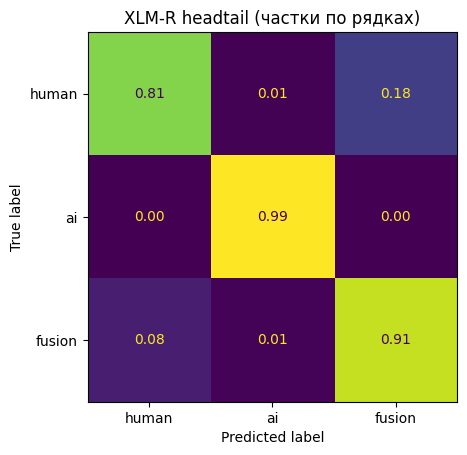

короткі (≤510) {'head': 0.9168, 'headtail': 0.9168, 'chunks': 0.9168}
довгі (>510) {'head': 0.6546, 'headtail': 0.8983, 'chunks': 0.6939}


In [7]:
best_mode = max(val_probs, key=lambda k: macro_f1(y_val, val_probs[k]))
pred = val_probs[best_mode].argmax(1)
print('Найкращий варіант:', best_mode)
print(classification_report(y_val, pred, target_names=LABELS, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred, normalize='true'), display_labels=LABELS).plot(
    colorbar=False, values_format='.2f')
plt.title(f'XLM-R {best_mode} (частки по рядках)'); plt.show()

# чи модель краща на коротких чи на довгих текстах
long_mask = lens > BODY
for name, m in [('короткі (≤510)', ~long_mask), ('довгі (>510)', long_mask)]:
    if m.any():
        print(name, {k: round(f1_score(y_val[m], p[m].argmax(1), average='macro'), 4) for k, p in val_probs.items()})

## 5. Передбачення на test і збереження ймовірностей

In [8]:
t0 = time.time()
test_probs = {'head': predict(model, ids_test, 'head'), 'headtail': predict(model, ids_test, 'headtail')}
test_probs['chunks'], test_chunk_max = predict(model, ids_test, 'chunks')
print(f'test inference {time.time() - t0:.0f}s')

for k in val_probs:
    np.save(f'{OUT_DIR}/xlmr_{k}_val_proba.npy', val_probs[k])
    np.save(f'{OUT_DIR}/xlmr_{k}_test_proba.npy', test_probs[k])
np.save(f'{OUT_DIR}/xlmr_chunkmax_val_proba.npy', val_chunk_max)
np.save(f'{OUT_DIR}/xlmr_chunkmax_test_proba.npy', test_chunk_max)
val[['id']].to_csv(f'{OUT_DIR}/val_ids.csv', index=False)

sub = pd.DataFrame({'id': test['id'].values, 'label': np.array(LABELS)[test_probs[best_mode].argmax(1)]})
sub = sample_sub[['id']].merge(sub, on='id', how='left')
if not DEBUG:
    assert len(sub) == len(sample_sub) and sub['label'].notna().all() and sub['id'].is_unique
sub.to_csv(f'{OUT_DIR}/submission_xlmr_{best_mode}.csv', index=False)
print(sub['label'].value_counts(normalize=True).round(3))

test inference 647s
label
ai        0.517
fusion    0.248
human     0.235
Name: proportion, dtype: float64
